In [453]:
import numpy as np
import pylab as plt
import scipy as sp
import pickle
import imageio
import os
from scipy.interpolate import interp1d
from scipy.special import gamma
from scipy.integrate import odeint

In [454]:
#Constants
BohrMagneton=9.7e-24
Boltzmann=1.38e-23
amu=1.6e-27

In [455]:
#Defaults 
BohrRad=5.3e-11
rho_ref=1e18
sigma_ref=4.52e-20
sigma0=3.5e-13


In [456]:
sigma0

3.5e-13

In [457]:
#Various useful series
theta=np.linspace(0,6.3,100)
XC=np.cos(theta)
SC=np.sin(theta)
XX,YY=np.meshgrid(np.linspace(-1,1,100),np.linspace(-1,1,100))
ZZ=XX+complex(0,1)*YY

In [458]:
def alpha(N):
    return np.sin((1/2+1/N)*np.pi)/(2*np.pi*(1/4-1/N**2))

def etaT( N,MaxB,T):
    return alpha(N)*BohrMagneton/(Boltzmann*T)

def equilR(eta,N,phi,sigma,v):
    return 2/(np.pi*gamma((N+2)/(N-2)))*eta**(2/(N-2))*phi*sigma/v

def Potential(rp,eta,N):
    return eta*rp**(N/2-1)

def DensityFixedR(rp,eta,N,phi,v,R):
    return phi*eta**(4/(N-2))/(np.pi*v*sp.special.gamma((N+2)/(N-2))*R**2)*np.exp(-eta*rp**(N/2-1))

def EKin(rp,eta,N,phi,v,R):
    return 3/2*DensityFixedR(rp,eta,N,phi,v,R)

def EPot(rp,eta,N,phi,v,R):
    return DensityFixedR(rp,eta,N,phi,v,R)*Potential(rp,eta,N)

def etacut(rp,eta,N):
    return((1-(rp)**(N/2-1))*eta)

def gam(eta,N,phi,sigma,v,R):
    return 4/(np.pi*gamma((N+2)/(N-2)))*eta**(+2/(N-2))*phi*sigma/(v*R)

In [459]:
#Load gamma

f=open("./GammaFile_T1K_rho1e18.pkl",'rb')
LogGammaE,LogGammaN=pickle.load(f)
f.close()
GammaN=lambda eta: np.exp(LogGammaN(eta))
GammaE=lambda eta: np.exp(LogGammaE(eta))

In [460]:
#Loss functions

def TotalLosses(eta,N,phi,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particlelosses=sum(GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)*DensityFixedR(rps,eta,N,phi,v,R)*(2*np.pi*rps)*R**2/bins)
    kinlosses=sum(EKin(rps,eta,N,phi,v,R)*GammaE(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)* (2.*np.pi*rps)*R**2/bins)
    potlosses=sum(EPot(rps,eta,N,phi,v,R)*GammaN(etacut(rps,eta,N))*(DensityFixedR(rps,eta,N,phi,v,R)/rho_ref)*(sigma0/sigma_ref)* (2.*np.pi*rps)*R**2/bins)
    energylosses=kinlosses+potlosses
    return(np.array([particlelosses,kinlosses,potlosses,energylosses]))

def TotalCounts(eta,N,phi,v,R,bins=1000):
    rps=np.linspace(0,1,bins)
    particles=sum(DensityFixedR(rps,eta,N,phi,v,R)*(2*np.pi*rps)*R**2/bins)
    kin=sum(EKin(rps,eta,N,phi,v,R)* (2.*np.pi*rps)*R**2/bins)
    pot=sum(EPot(rps,eta,N,phi,v,R)* (2.*np.pi*rps)*R**2/bins)
    energy=kin+pot
    return(np.array([particles,kin,pot,energy]))

def FracLosses(eta,N,phi,v,R,bins=1000):
    return(TotalLosses(eta,N,phi,v,R,bins)/TotalCounts(eta,N,phi,v,R,bins))

In [461]:

def GetLnGradients_Eta_N_R(p,z):
    T=np.exp(p[0])
    phi=np.exp(p[1])
    Losses=FracLosses(fEta(z),fN(z),phi,v0,fR(z))*np.sqrt(T)/v0
    return(-(Losses[3]-Losses[0]),-Losses[0])

def GetLnGradients_B_N_R(p,z):
    T=np.exp(p[0])
    phi=np.exp(p[1])
    eta=fB(z)*BohrMagneton*alpha(fN(z))/(T*Boltzmann)
    Losses=FracLosses(eta,fN(z),phi,v0,fR(z))*np.sqrt(T)/v0
    return(-(Losses[3]-Losses[0]),-Losses[0])





In [462]:
#Set up three functions, fN, fR, fEta, and two initial conditions phi0, T0


z0=0


AllZs=[]
AllTs=[]
AllPhis=[]

AllRs=[]
AllNs=[]
AllEtas=[]
AllVs=[]


phi0=4e11
v0=6.8
T0=0.2
M=6*amu

Ls=np.array([1])
Ns=[8]
Bs=[0.5]
R0s=list(np.linspace(0.03,0.01,100))


for Li in range(0,len(Ls)):
    L=Ls[Li]
    N0=Ns[Li]
    B0=Bs[Li]
    zs=np.linspace(0,L,100)

    
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,R0s,bounds_error=False,fill_value='extrapolate')    
    fB=interp1d(zs,list((np.ones_like(zs))*B0),bounds_error=False,fill_value='extrapolate')

    GetLnGradients=GetLnGradients_B_N_R

    sol=odeint(GetLnGradients,[np.log(T0),np.log(phi0)],zs)
    AllPhis+=list(np.exp(sol[:,1]))
    AllTs+=list(np.exp(sol[:,0]))
    AllVs+=list(v0*np.ones_like(zs))
    AllNs+=list((np.ones_like(zs))*N0)
    AllZs+=list(z0+zs)
    AllRs+=list(fR(z0+zs))



In [463]:
B0

0.5

(0.0, 0.5)

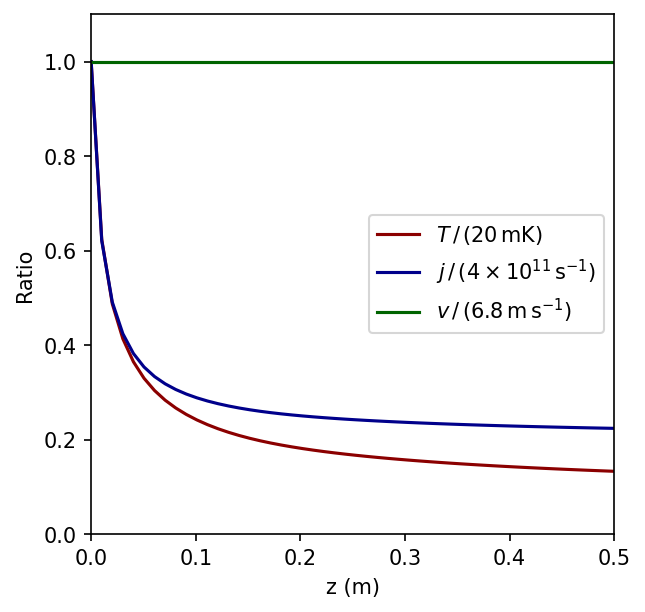

In [464]:


plt.figure(figsize=(4.5,4.5),dpi=150)


plt.plot(AllZs,np.array(AllTs)/AllTs[0],label=r'$T\, / \,(20 \,\mathrm{mK})$',color='DarkRed')
plt.plot(AllZs,np.array(AllPhis)/AllPhis[0],label=r'$j\, / \,(4\times10^{11}\,\mathrm{s}^{-1})$',color='DarkBlue')
plt.plot(AllZs,np.array(AllVs)/AllVs[0],label=r'$v\, /\, (6.8\, \mathrm{m\,s}^{-1})$',color='DarkGreen')
plt.legend(loc='center right')
plt.xlabel("z (m)")
plt.ylabel("Ratio")
#plt.xlim(0,600)
#plt.plot([0,6],[1//60,1/60],'--',color='blue')
plt.ylim(0,1.1)
#plt.semilogy()
plt.xlim(0,0.5)
#plt.title(r"$j_0=4\times10^{11}\,\mathrm {s}^{-1}, v_0 = 11.5 \,\mathrm{m\,s}^{-1}, T_0=0.2\, \mathrm{K}$")

In [465]:
(7/16)*2.3**2

2.3143749999999996

In [466]:
10/np.sqrt(6*np.pi)

2.3032943298089035

In [467]:
(1-0.75**2)*2.3**2

2.3143749999999996

<>:4: SyntaxWarning: invalid escape sequence '\z'
<>:4: SyntaxWarning: invalid escape sequence '\z'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_60589/3597404469.py:4: SyntaxWarning: invalid escape sequence '\z'
  plt.ylabel("$\zeta$")


(0.0, 1.0)

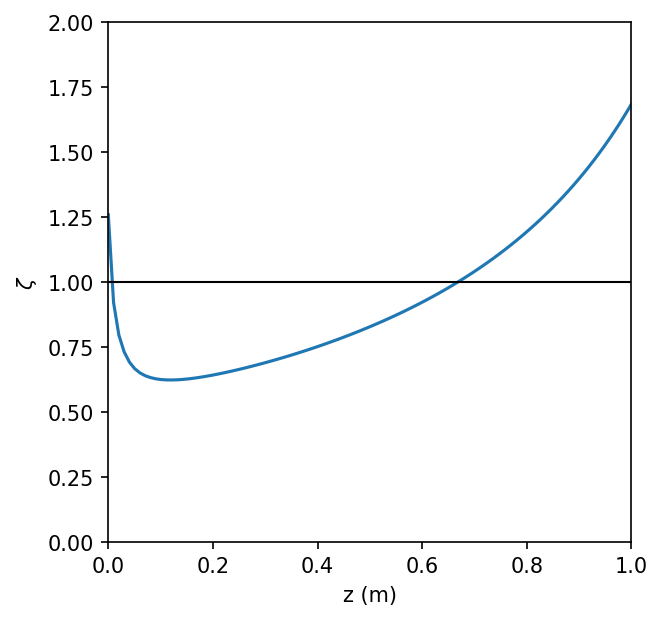

In [468]:
plt.figure(figsize=(4.5,4.5),dpi=150)
plt.plot(AllZs,gam(alpha(np.array(AllNs))*BohrMagneton/(Boltzmann*np.array(AllTs)),np.array(AllNs),np.array(AllPhis),sigma0,np.array(AllVs),np.array(AllRs)))
plt.xlabel("z (m)")
plt.ylabel("$\zeta$")
plt.plot([0,1],[1,1],'-',color='black',linewidth=1)
plt.ylim(0,2)
plt.xlim(0,1)


In [469]:
#Set up three functions, fN, fR, fEta, and two initial conditions phi0, T0

v0=6.8*0.75
T0=0.06
phi0=1e11
z0=0


AllPhis=[phi0,phi0]
AllTs=[0.02,0.06]
AllVs=[6.8,6.8*0.75]
AllNs=[N0,N0]
AllEtas=[etas[0],etas[0]]
AllRs=[Rs[0],Rs[0]]
AllZs=[0,0]


B0=0.5
R0=0.02
N0=8
eta0=8.5


Ls=np.array([1,1,1,1,1,1])
etas=[9.5,9.3,10.4,10.4,11.5,11.5]
Ns=[8,8,6,6,4,4]
Rs=[0.01,0.01,0.0075,0.0075,0.0075,0.0075]








for Li in range(0,len(Ls)):
    L=Ls[Li]
    eta0=etas[Li]
    N0=Ns[Li]
    R0=Rs[Li]
    zs=np.linspace(0,L,100)

    
    
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,list((np.ones_like(zs))*R0),bounds_error=False,fill_value='extrapolate')    
    fEta=interp1d(zs,list((np.ones_like(zs))*eta0),bounds_error=False,fill_value='extrapolate')
    
    GetLnGradients=GetLnGradients_Eta_N_R

    sol=odeint(GetLnGradients,[np.log(T0),np.log(phi0)],zs)
    AllPhis+=list(np.exp(sol[:,1]))
    AllTs+=list(np.exp(sol[:,0]))

    AllVs+=list(v0*np.ones_like(zs))
    
    AllNs+=list((np.ones_like(zs))*N0)
    AllEtas+=list((np.ones_like(zs))*eta0)
    AllRs+=list(np.ones_like(zs)*R0)
    AllZs+=list(z0+zs)
    z0=AllZs[-1]
    
    T0=AllTs[-1]*3
    phi0=AllPhis[-1]
    v0=AllVs[-1]*0.75
    #print(AllTs,AllPhis)

Text(0.5, 1.0, '$j_0=1\\times10^{11}\\,\\mathrm {s}^{-1}, v_0 = 6.8\\, \\mathrm{m\\,s}^{-1}, T_0=0.02\\, \\mathrm{K}$')

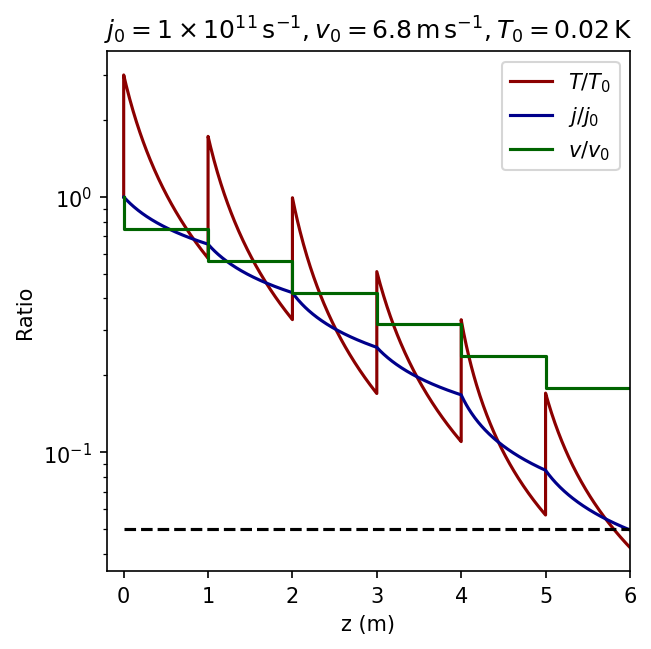

In [470]:
plt.figure(figsize=(4.5,4.5),dpi=150)
plt.plot(AllZs,np.array(AllTs)/AllTs[0],label=r'$T/T_0$',color='DarkRed')
plt.plot(AllZs,np.array(AllPhis)/AllPhis[0],label=r'$j/j_0$',color='DarkBlue')
plt.plot(AllZs,np.array(AllVs)/AllVs[0],label=r'$v/v_0$',color='DarkGreen')
plt.legend(loc='upper right')
plt.xlabel("z (m)")
plt.ylabel("Ratio")
#plt.xlim(0,600)
plt.plot([0,6],[1/20,1/20],'--',color='black')
#plt.ylim(0,1.1)
plt.semilogy()
plt.xlim(-0.2,6)
plt.title(r"$j_0=1\times10^{11}\,\mathrm {s}^{-1}, v_0 = 6.8\, \mathrm{m\,s}^{-1}, T_0=0.02\, \mathrm{K}$")

(-0.2, 6.2)

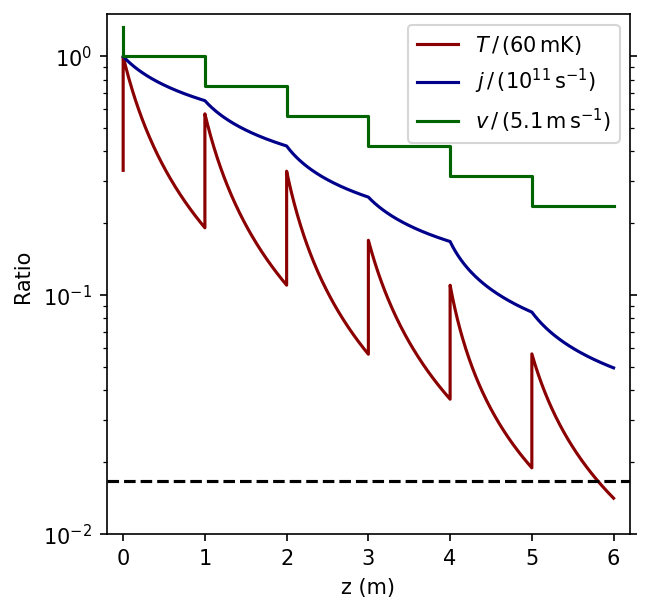

In [471]:
plt.figure(figsize=(4.5,4.5),dpi=150)
plt.plot(AllZs,np.array(AllTs)/AllTs[1],label=r'$T\, / \,(60 \,\mathrm{mK})$',color='DarkRed')
plt.plot(AllZs,np.array(AllPhis)/AllPhis[1],label=r'$j\, / \,(10^{11}\,\mathrm{s}^{-1})$',color='DarkBlue')
plt.plot(AllZs,np.array(AllVs)/AllVs[1],label=r'$v\, /\, (5.1\, \mathrm{m\,s}^{-1})$',color='DarkGreen')
plt.legend(loc='upper right')
plt.xlabel("z (m)")
plt.ylabel("Ratio ")
#plt.xlim(0,600)
plt.plot([-0.2,6.2],[1/60,1/60],'--',color='black')
plt.ylim(1e-2,1.5)
plt.semilogy()
ax=plt.gca()
ax.yaxis.set_ticks_position('both')
plt.xlim(-0.2,6.2)
#plt.title(r"$j_0=1\times10^{11}\,\mathrm {s}^{-1}, v_0 = 5.1\, \mathrm{m\,s}^{-1}, T_0=0.06\, \mathrm{K}$")

<>:24: SyntaxWarning: invalid escape sequence '\z'
<>:24: SyntaxWarning: invalid escape sequence '\z'
/var/folders/x8/m88g9m690wb3gf4t7ds85nzw0000gn/T/ipykernel_60589/1466683233.py:24: SyntaxWarning: invalid escape sequence '\z'
  ax5.set_ylabel("$\zeta$")


Text(0.5, 0, 'z (m)')

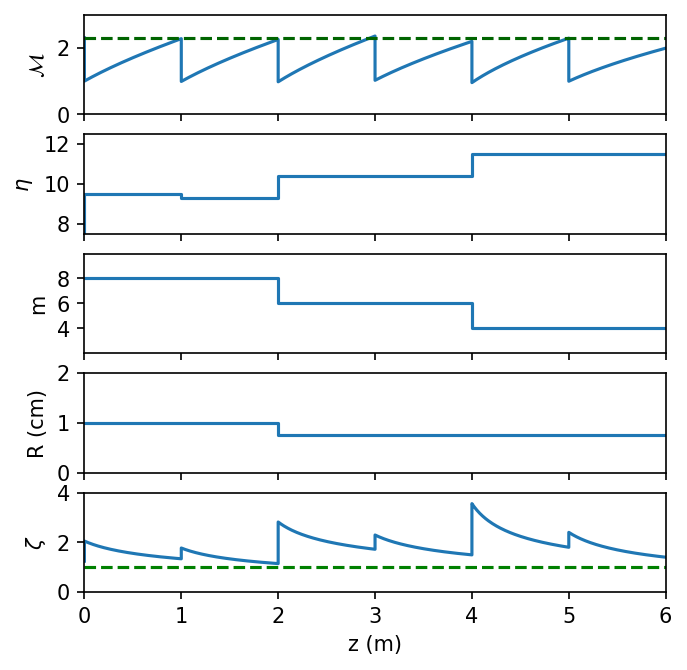

In [472]:

fig, (ax1, ax2,ax3,ax4,ax5) = plt.subplots(5, sharex=True,dpi=150,figsize=(5,5))
Boltzmann=8.6e-5
BohrMagneton=5.7e-5
ax1.plot(AllZs,2.3*np.array(AllVs)/AllVs[0]/np.sqrt(np.array(AllTs)/AllTs[0]))
ax1.set_ylabel(r"$\mathcal{M}$")
ax1.plot([0,600],[2.3,2.3],'--',color='DarkGreen')

ax1.set_ylim([0,3])
ax1.set_xlim(0,6)
ax2.plot(AllZs,np.array(AllEtas))
ax2.set_ylabel(r"$\eta$")
ax2.set_ylim(7.5,12.5)
ax2.set_yticks([8,10,12])
ax3.plot(AllZs,np.array(AllNs))
ax3.set_ylabel("m")
ax3.set_ylim(2,10)
ax3.set_yticks([4,6,8])
ax4.plot(AllZs,np.array(AllRs)*100)
ax4.set_ylim(0,2)
ax4.set_ylabel("R (cm)")
ax4.set_yticks([0,1,2])
ax5.plot(AllZs,gam(np.array(AllEtas),np.array(AllNs),np.array(AllPhis),sigma0,np.array(AllVs),np.array(AllRs)))
#ax5.set_ylim(11.5,14.5)
ax5.set_ylabel("$\zeta$")
ax5.set_ylim([0,4])
plt.plot([0,6],[1,1],'--',color='green')
ax5.set_xlabel("z (m)")

#ax2.set_ylim(1e-3,0.7)


In [473]:
from scipy.special import gammaincc
from scipy.special import gamma

def Gam(a,x):
    return gammaincc(a,x)*gamma(a)
def Gam0(a):
    return gamma(a)



In [474]:
T0=1
phi0=1e19

N0s=[4]
eta0s=[5]
R0s=[0.01]
z0s=[0,1]

AllZs=[]
AllTs=[]
Allphis=[]

for si in range(0,len(N0s)):
    N0=N0s[si]
    eta0=eta0s[si]
    R0=R0s[si]
    zs=np.linspace(z0s[si],z0s[si+1],1000)
    InitCond=[np.log(T0),np.log(phi0)]
    
    fN=interp1d(zs,list((np.ones_like(zs))*N0),bounds_error=False,fill_value='extrapolate')
    fR=interp1d(zs,list((np.ones_like(zs))*R0),bounds_error=False,fill_value='extrapolate')    
    fEta=interp1d(zs,list((np.ones_like(zs))*eta0),bounds_error=False,fill_value='extrapolate')
    sol=odeint(GetLnGradients,InitCond,zs)
    
    AllTs+=list(np.exp(sol[:,0]))
    Allphis+=list(np.exp(sol[:,1]))



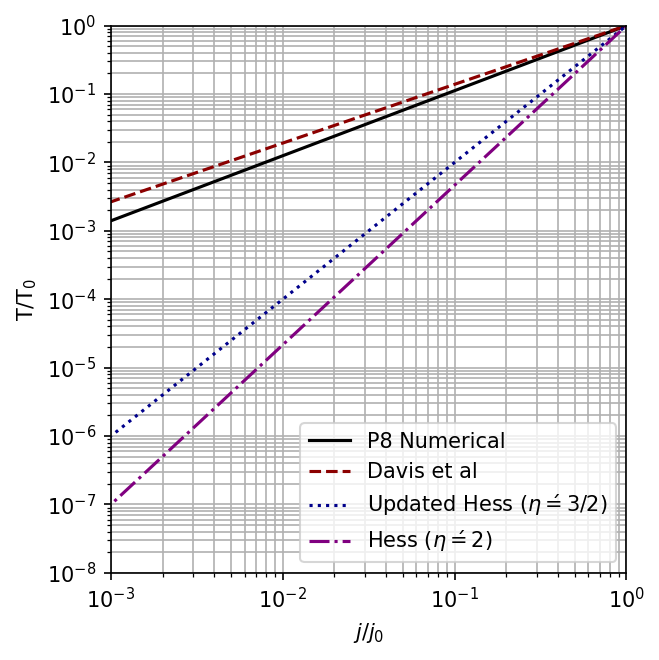

In [475]:
plt.figure(figsize=(4.5,4.5),dpi=150)

d=2
m=1
ketgam=(Gam(5/2+d/m,5)/Gam0(5/2+d/m))/(Gam(3/2+d/m,5)/Gam0(3/2+d/m))-1

plt.ylabel("T/T$_0$")
plt.xlabel("$j$/$j_0$")
plt.loglog()
vars=np.logspace(-4,0)
plt.plot(np.array(Allphis)/Allphis[0],np.array(AllTs)/AllTs[0],'-',color='black',label='P8 Numerical')

plt.plot(vars,vars**ketgam,'--',label='Davis et al',color='DarkRed')
plt.plot(vars,vars**2,':',label=r'Updated Hess ($\eta\'=3/2$)',color='DarkBlue')
plt.plot(vars,vars**(7/3),'-.',label=r'Hess ($\eta\'=2$)',color='purple')
plt.grid(which='both')
plt.legend(loc='lower right')
plt.xlim(1e-3,1)
plt.ylim(1e-8,1)
plt.tight_layout()
plt.savefig("PhiNu.pdf",dpi=200,bbox_inches='tight')

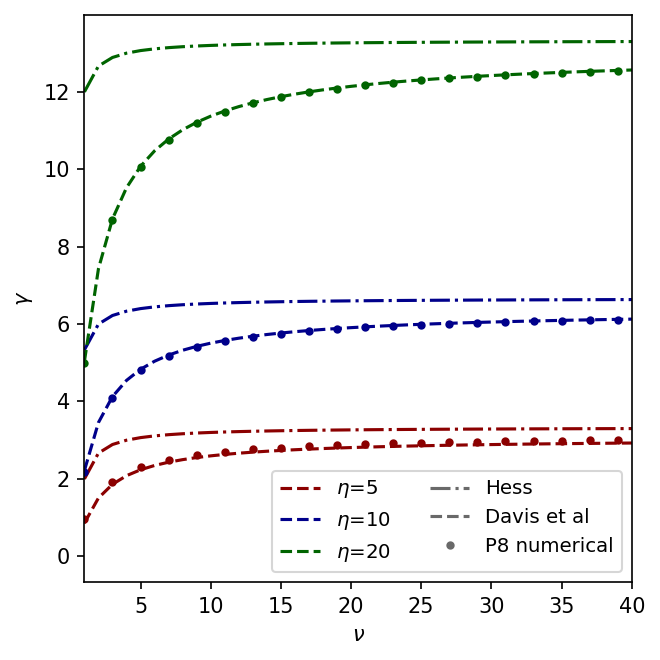

In [476]:

def GetLnGradientsSpec(p,t):
    T=np.exp(p[0])
    phi=np.exp(p[1])
    #R=equilR(eta0,N0,phi,sigma,v0)
    R=R0
    Losses=FracLosses(eta0,N0,phi,v0,R)*np.sqrt(T)
    return(-(Losses[3]-Losses[0]),-Losses[0])
    
plt.figure(figsize=(4.5,4.5),dpi=150)
m=np.arange(1,100,1)
etas=[5,10,20]
Colors=['DarkRed','DarkBlue','DarkGreen']
i=0
d=2
for eta in etas:
    for m0 in np.arange(1,100,2):
        N0=2*(m0+1)
        eta0=eta
        g1,g2=GetLnGradientsSpec((2,1),1)
        plt.plot(m0,g1/g2,'.',color=Colors[i])
    ketgam=(Gam(5/2+d/m,eta)/Gam0(5/2+d/m))/(Gam(3/2+d/m,eta)/Gam0(3/2+d/m))-1
    HessGam=2/3*(eta-2/m)
    plt.plot(m,ketgam,'--',color=Colors[i],label=r'$\eta$='+str(eta))
    plt.plot(m,HessGam,'-.',color=Colors[i])
    i=i+1
    plt.xlim(1,40)
plt.plot([0],[0],'-.',color='dimgrey',label='Hess')
plt.plot([0],[0],'--',color='dimgrey',label='Davis et al')
plt.plot([0],[0],'.',color='dimgrey',label='P8 numerical')
plt.legend(loc='lower right',ncol=2,fontsize=9.5)
plt.xlabel(r"$\nu$")
plt.ylabel(r"$\gamma$")

plt.tight_layout()
plt.savefig("GamVsNu.png",dpi=200,bbox_inches='tight')


In [477]:
#Effusive velocity
T=0.2
Boltzmann=1.38e-23
M=6*amu
np.sqrt(Boltzmann*T/M)*(1/np.sqrt(2*np.pi))

6.764395474757513